In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv("smartcart_customers.csv")

In [4]:
df.head()
df.shape

(2240, 22)

In [5]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
Complain                0
Response                0
dtype: int64

# Data Preprocessing

In [6]:
# Handle missing Values
df["Income"]=df["Income"].fillna(df["Income"].median())
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0


In [7]:
#feature engineerig- Age and customer joined days
df["Age"]=2026-df["Year_Birth"]
df["Dt_Customer"]=pd.to_datetime(df["Dt_Customer"], dayfirst=True)
reference_date=df["Dt_Customer"].max()
df["customer_tenure_date"]=(reference_date-df["Dt_Customer"]).dt.days

In [8]:
# spending, children
df["total_spending"]=df["MntWines"]+df["MntFruits"]+df["MntMeatProducts"]+df["MntFishProducts"]+df["MntSweetProducts"]+df["MntGoldProds"]
df["total_children"]=df["Kidhome"]+df["Teenhome"]

#Education
df["Education"].value_counts()
df["Education"]=df["Education"].replace({
    "Basic":"Undergraduate","2n Cycle":"Undergraduate",
    "Graduation":"Graduate",
    "Master":"Postgraduate","PhD":"Postgraduate"
}
    
)
# Maritial status
df["Marital_Status"].value_counts()
df["Living_with"]=df["Marital_Status"].replace({
    "Married":"Partner","Together":"Partner",
    "Single":"Alone","Divorced":"Alone",
     "Widow":"Alone","Absurd":"Alone","YOLO":"Alone"
})

In [9]:
df["Living_with"].value_counts()
df["Education"].value_counts()

Education
Graduate         1127
Postgraduate      856
Undergraduate     257
Name: count, dtype: int64

In [10]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response', 'Age', 'customer_tenure_date', 'total_spending',
       'total_children', 'Living_with'],
      dtype='object')

In [11]:
# drop unnecessary columns
cols=["ID","Year_Birth","Marital_Status","Kidhome","Teenhome","Dt_Customer",'MntWines', 'MntFruits',
      'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts','MntGoldProds']
df_cleaned=df.drop(columns=cols)

In [12]:
df.shape

(2240, 27)

In [13]:
df_cleaned.shape

(2240, 15)

# Outliers

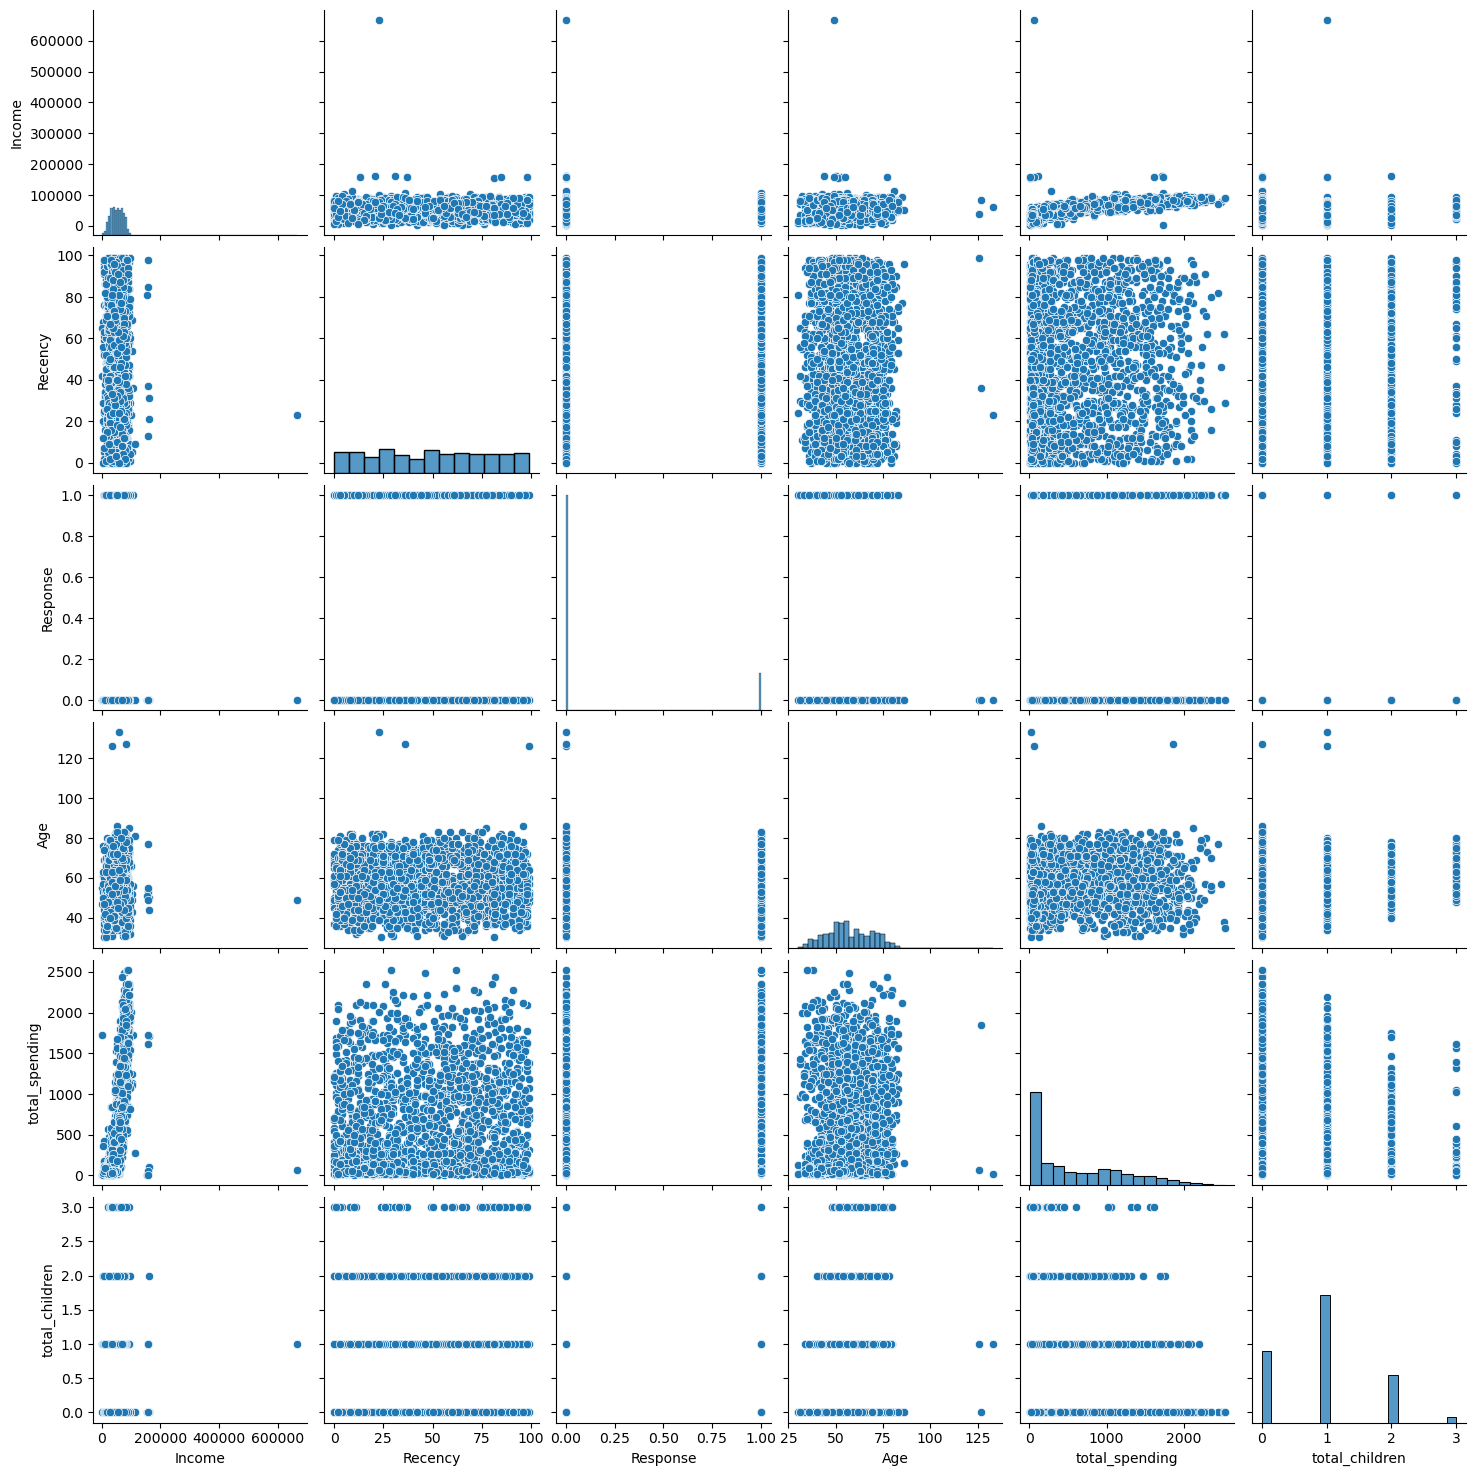

In [14]:
cols=['Income','Recency','Response', 'Age','total_spending','total_children']
sns.pairplot(df_cleaned[cols])

In [15]:
df_cleaned=df_cleaned[(df_cleaned["Age"]<90)]
df_cleaned=df_cleaned[(df_cleaned["Income"]<600000)]
df_cleaned.shape

(2236, 15)

# Heatmap


<Axes: >

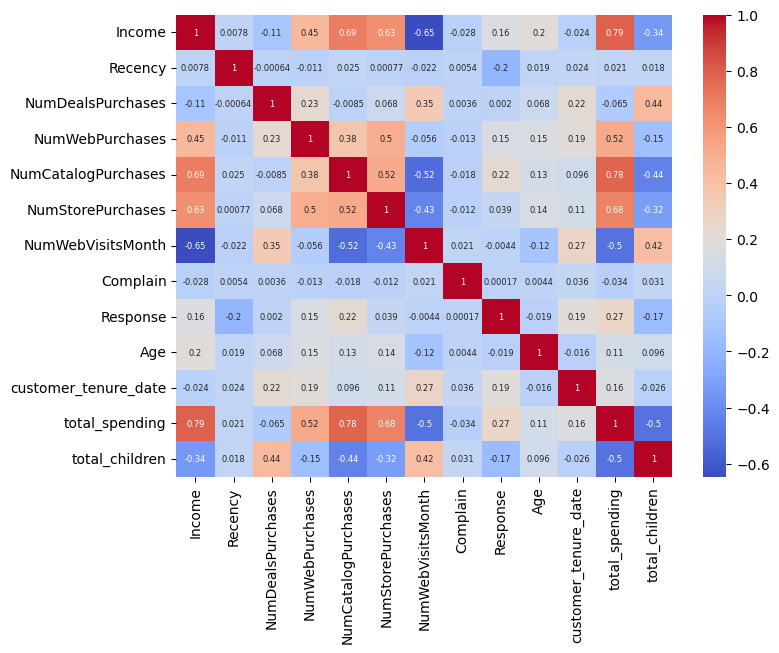

In [16]:
corr=df_cleaned.corr(numeric_only=True)
plt.figure(figsize=(8,6))
sns.heatmap(corr,annot=True,annot_kws={"size":6},cmap="coolwarm")

In [17]:
df_cleaned.shape

(2236, 15)

# Encoding

In [18]:
from sklearn.preprocessing import OneHotEncoder
ohe=OneHotEncoder()
catogerical_cols=["Education","Living_with"]
encoded_cols=ohe.fit_transform(df_cleaned[catogerical_cols])

In [19]:
enc_df=pd.DataFrame(encoded_cols.toarray(),columns=ohe.get_feature_names_out(catogerical_cols),index=df_cleaned.index)
enc_df.head()

,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_with_Alone,Living_with_Partner
0,1.0,0.0,0.0,1.0,0.0
1,1.0,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,0.0,1.0
3,1.0,0.0,0.0,0.0,1.0
4,0.0,1.0,0.0,0.0,1.0


In [20]:
df_encoded=pd.concat([df_cleaned.drop(columns=catogerical_cols),enc_df], axis=1)
df_encoded.shape


(2236, 18)

# Scaling

In [21]:
from sklearn.preprocessing import StandardScaler
X=df_encoded
sc=StandardScaler()
sc_data=sc.fit_transform(X)
sc_data.shape

(2236, 18)

# Visualize


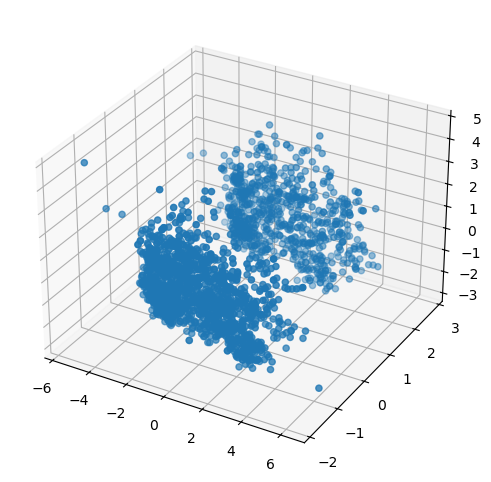

In [39]:
from sklearn.decomposition import PCA
pca=PCA(n_components=3)
x_pca=pca.fit_transform(sc_data)

fig=plt.figure(figsize=(8,6))
ax=fig.add_subplot(111,projection="3d")
ax.scatter(x_pca[:,0],x_pca[:,1],x_pca[:,2])

# Analyze K- Elbow and Silhoute scor


In [40]:
from sklearn.cluster import KMeans
from kneed import KneeLocator

wcss=[]
for k in range(1,11):
    kmeans=KMeans(n_clusters=k,random_state=42)
    kmeans.fit_predict(x_pca)
    wcss.append(kmeans.inertia_)
    
    

In [45]:
knee=KneeLocator(range(1,11),wcss,curve="convex",direction="decreasing")
optimal_k=knee.elbow
print("optimal_k value : ",optimal_k)

optimal_k value :  4


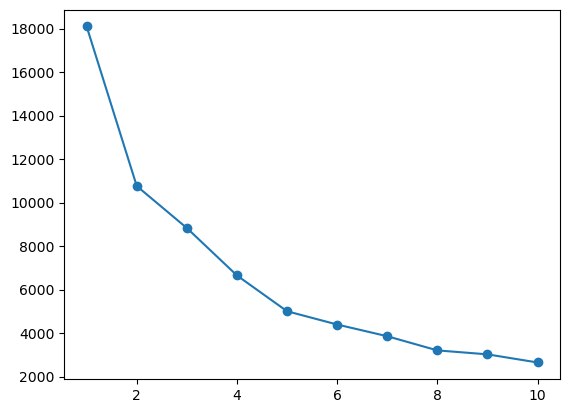

In [48]:
plt.plot(range(1,11),wcss,marker="o")



In [56]:
# Silhoutte score
from sklearn.metrics import silhouette_score
ss=[]
for k in range(2,11):
    kmeans=KMeans(n_clusters=k,random_state=42)
    labels= kmeans.fit_predict(x_pca)
    score=silhouette_score(x_pca,labels)
    ss.append(score)


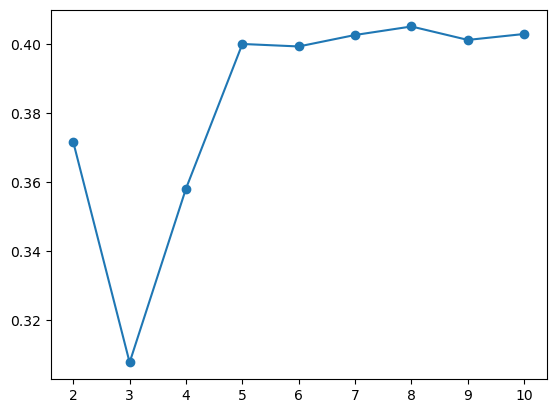

In [57]:
plt.plot(range(2,11),ss,marker="o")


# Clustering K means

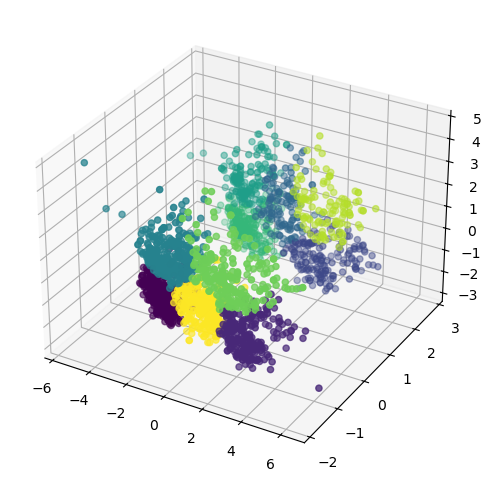

In [60]:
kmeans=KMeans(n_clusters=k,random_state=42) 
labels=kmeans.fit_predict(x_pca)

fig=plt.figure(figsize=(8,6))
ax=fig.add_subplot(111,projection="3d")
ax.scatter(x_pca[:,0],x_pca[:,1],x_pca[:,2],c=labels)

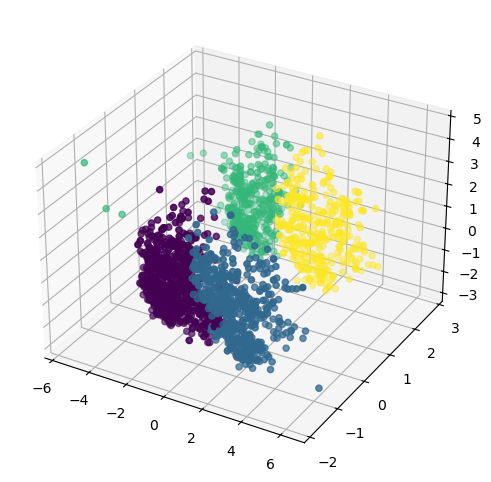

In [63]:
from sklearn.cluster import AgglomerativeClustering
agg=AgglomerativeClustering(n_clusters=4,linkage="ward")
agglabel=agg.fit_predict(x_pca)

fig=plt.figure(figsize=(8,6))
ax=fig.add_subplot(111,projection="3d")
ax.scatter(x_pca[:,0],x_pca[:,1],x_pca[:,2],c=agglabel)

# Characterization

<Axes: xlabel='labels', ylabel='count'>

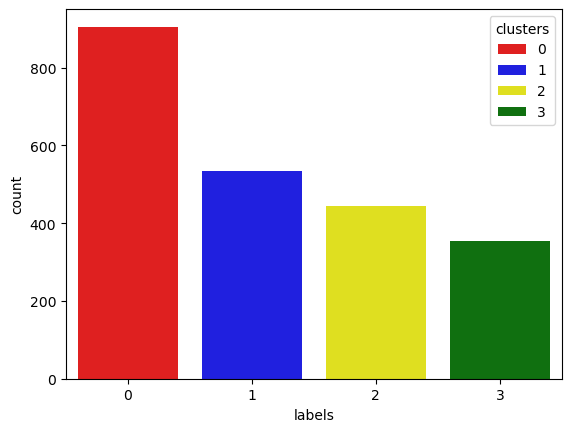

In [74]:
df_cleaned.drop("labels",axis=1)
X["clusters"]=agglabel


pal=["red","blue","yellow","green"]
sns.countplot(x=df_cleaned["labels"], palette=pal,hue=X["clusters"])

<Axes: xlabel='total_spending', ylabel='Income'>

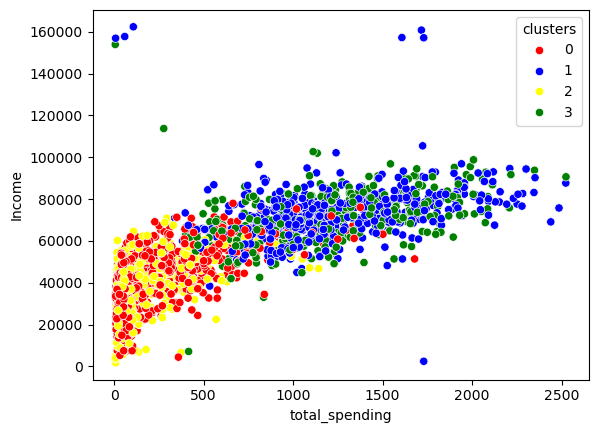

In [76]:
sns.scatterplot(x=X["total_spending"],y=X["Income"],hue=X["clusters"],palette=pal)

In [77]:
cluster_summary=X.groupby("clusters").mean()
print(cluster_summary)

                Income    Recency  NumDealsPurchases  NumWebPurchases  \
clusters                                                                
0         39680.580110  48.914917           2.594475         3.153591   
1         72808.445693  49.202247           1.958801         5.687266   
2         36960.143018  48.319820           2.594595         2.713964   
3         70722.681303  50.504249           1.855524         5.790368   

          NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  Complain  \
clusters                                                                        
0                    0.969061           4.143646           6.307182  0.011050   
1                    5.498127           8.659176           3.580524  0.005618   
2                    0.837838           3.623874           6.659910  0.011261   
3                    5.014164           8.430595           3.728045  0.005666   

          Response        Age  customer_tenure_date  total_spending  \
clu